<a href="https://colab.research.google.com/github/gabrieltm-sudo/deeplearning/blob/ajustes/ProjetoI_DL_ClassificationMLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Course: Deep Learning
# Author: Sandro Camargo <sandrocamargo@unipampa.edu.br>
# Modificado por Gabriel Torres Machado - Projeto I
# Classification with Multi Layer Perceptron Example Phishing Websites
# Dataset: https://archive.ics.uci.edu/dataset/327/phishing+websites

To open this code in your Google Colab environment, [click here](https://colab.research.google.com/drive/1GTxXsF1f9dRAMot7C9ZQIB6OsQUenjhm?usp=sharing).

A Python library is a collection of related functions. A library contains bundles of encapsulated code which can be used repeatedly in different programs.

In [ ]:
# Import Libraries
import keras # Neural Network Library
from keras import layers # Layers to a neural network
from keras import optimizers # optimizers
import pandas as pd # Data Manipulation library
import numpy as np # Fast Numeric Computing library
import tensorflow as tf # Optimizers
import matplotlib.pyplot as plt # Plot library
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay
from tensorflow.keras.utils import plot_model # Print the network

In [ ]:
# import necessary additional library
from sklearn.model_selection import train_test_split
# from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay

In [ ]:
# Loading training dataset
# columns of dataset
colunas = [
    'having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol',
    'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State',
    'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL',
    'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL',
    'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain',
    'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page',
    'Statistical_report', 'Result'
]

data = pd.read_csv('sample_data/Training Dataset.arff', sep=",", header=None, names=colunas)
# About the parameters
# Header=1: column names (day, month, year, ...) are in the line 1 of this CSV file.
# skiprows=[124,125,126,170]: this lines, which not contains valid data, are not imported. If this parameter is missing, all lines are imported.
# usecols=list(range(0,13)): The last column, which is named Classes, is not imported. If this parameter is missing, all columns are imported.

# inspecting columns and data types from "data" dataframe
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   having_IP_Address            11055 non-null  int64
 1   URL_Length                   11055 non-null  int64
 2   Shortining_Service           11055 non-null  int64
 3   having_At_Symbol             11055 non-null  int64
 4   double_slash_redirecting     11055 non-null  int64
 5   Prefix_Suffix                11055 non-null  int64
 6   having_Sub_Domain            11055 non-null  int64
 7   SSLfinal_State               11055 non-null  int64
 8   Domain_registeration_length  11055 non-null  int64
 9   Favicon                      11055 non-null  int64
 10  port                         11055 non-null  int64
 11  HTTPS_token                  11055 non-null  int64
 12  Request_URL                  11055 non-null  int64
 13  URL_of_Anchor                11055 non-null  i

In [ ]:
# converting classes -1 and 1 to 0 and 1 (standard format for binary neural networks)
classes = data['Result'].map({-1: 0, 1: 1})

# separation of data.drop (features) and classes (target)
data.drop('Result', axis=1, inplace=True)

MinMaxScaler()


In [ ]:
# idk - i think it was unnecessary
#
#classestest = datatest.iloc[:,0]
#datatest.drop(datatest.columns[[0]], axis=1, inplace=True)
#scalertest = MinMaxScaler()
#print(scalertest.fit(datatest))
#datatest = pd.DataFrame(scaler.transform(datatest))

The dataset must be randomly splitted in two parts: training set and testing set. The main approaches to split are holdout and n-fold cross validation.
*   Training set is used for building (training) the model.
*   Testing set is used for testing the generalization ability of the model built.

Moreover, inputs($x$) and outputs($y$) must be splitted in each set.




In [ ]:
# Creating the training and testing dataset
train_x, test_x, train_y, test_y = train_test_split(
    data, classes, test_size=0.3, random_state=42
)

# Normalize using only training data
scaler = MinMaxScaler()
train_x = pd.DataFrame(
    scaler.fit_transform(train_x),
    columns=train_x.columns,
    index=train_x.index
)
test_x = pd.DataFrame(
    scaler.transform(test_x),
    columns=test_x.columns,
    index=test_x.index
)

# Verifying dataset dimensions
print('The training dataset (inputs) dimensions are: ', train_x.shape)
print('The training dataset (outputs) dimensions are: ', train_y.shape)
print('The testing dataset (inputs) dimensions are: ', test_x.shape)
print('The testing dataset (outputs) dimensions are: ', test_y.shape)

The training dataset (inputs) dimensions are:  (7738, 30)
The training dataset (outputs) dimensions are:  (7738,)
The testing dataset (inputs) dimensions are:  (3317, 30)
The testing dataset (outputs) dimensions are:  (3317,)


After creating the datasets, the next step is defining the architecture of our model.

It must be defined:


*   Architecture: in terms of neurons and layers
*   Optimizer: is the algorithm or method used to change the weights in order to minimize the loss function.

The last step is compiling the model. In this step the loss function, the optimizer and the evaluation metrics must be defined.

In [ ]:
# Function to define model architecture
def build_model():
  # Defining the architecture
  # Sequential = Feedforward Neural Network
  # 1 single neuron
  # input_shape is the amount of columns from training set
  model = keras.Sequential([
        layers.Input(shape=[len(train_x.columns)]),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid") # sigmoid or softmax
  ])

  # Defining the optimizer
  optimizer = tf.keras.optimizers.RMSprop(
      learning_rate = 0.001)

  # Mean Squared Error (MSE) is the default loss function in regression models
  model.compile(loss = 'binary_crossentropy', # binary or categorical _crossentropy
      optimizer = optimizer,
      metrics = ['accuracy'])

  return model

Just for curiosity, you should observe how many parameters ($\theta$) your model has.
At this point, your model is built.

In [ ]:
model = build_model()
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

After creating the model, it must be trained (fitted).
Training is done using training set and the amount of epochs must be defined.

In [ ]:
EPOCHS = 50

history = model.fit(
    train_x, train_y, epochs = EPOCHS, verbose = 1
)

Epoch 1/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8323 - loss: 0.4381
Epoch 2/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9137 - loss: 0.2456
Epoch 3/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9209 - loss: 0.2116
Epoch 4/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9241 - loss: 0.1984
Epoch 5/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9269 - loss: 0.1899
Epoch 6/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9302 - loss: 0.1838
Epoch 7/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9315 - loss: 0.1780
Epoch 8/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9328 - loss: 0.1738
Epoch 9/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9329 - loss: 0.1711
Epoch 10/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9351 - loss: 0.1676
Epoch 11/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9365 - loss: 0.1652
Epoch 12/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

This plot should be generated just to inspect the learning convergence.
It is expected a decreasing of the loss function value through the epochs.


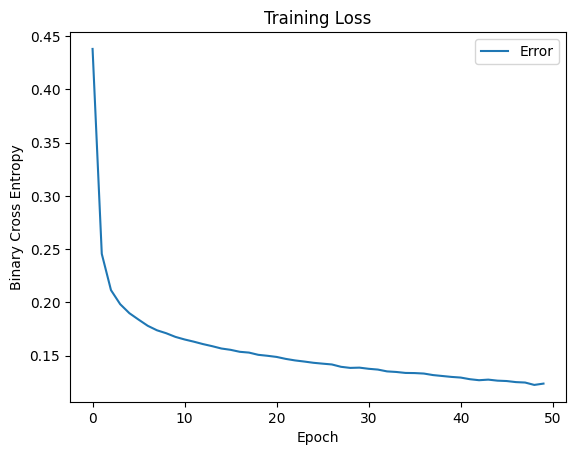

In [ ]:
plt.plot(history.history['loss']) # loss or categorical_crossentropy
plt.title('Training Loss')
plt.ylabel('Binary Cross Entropy')
plt.xlabel('Epoch')
plt.legend(['Error'], loc='upper right')
plt.savefig("mlp-class-lossfunction.png")
plt.show()

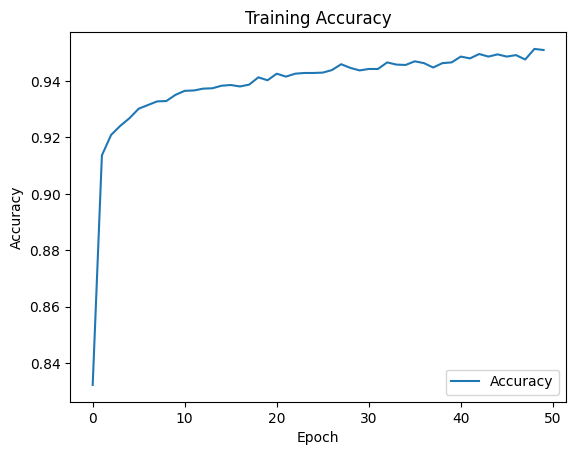

In [ ]:
plt.plot(history.history['accuracy'])
plt.title('Training Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Accuracy'], loc='lower right')
plt.savefig("mlp-class-trainingaccuracy.png")
plt.show()

In [ ]:
weights = model.get_weights() # return a numpy list of weights
print(type(weights))
print(weights)

<class 'list'>
[array([[ 1.70777127e-01,  4.09552231e-02,  2.53552169e-01,
        -4.21785265e-02, -1.95498258e-01, -2.13196963e-01,
         3.21205467e-01,  1.00844391e-01,  5.40010154e-01,
        -1.52898654e-01, -1.02081038e-01,  1.11603960e-02,
         1.88894458e-02, -8.40651467e-02, -1.75884753e-01,
        -1.84726000e-01,  3.17602768e-03,  2.54627708e-02,
         3.91345650e-01, -3.00742030e-01,  3.02813172e-01,
         1.33449897e-01,  2.09749416e-02,  2.51167208e-01,
         3.64928186e-01, -1.19560325e+00, -6.60428181e-02,
        -1.16082609e-01, -1.00016415e-01,  2.06844240e-01,
         1.62495643e-01, -1.68316275e-01],
       [-7.51418293e-01,  5.29215813e-01,  3.86464328e-01,
        -1.80112407e-01, -8.92417431e-02, -1.44293815e-01,
         5.38069345e-02,  8.19842368e-02, -3.91655207e-01,
         2.01678708e-01, -9.81777549e-01, -2.50931054e-01,
        -3.61658573e-01, -3.45521897e-01, -9.20153499e-01,
         8.73813182e-02,  9.63815227e-02,  3.01857948e-0

After the training process, the knowledge learnt by a neural network is stored in its weights.

After the training process, the model should be tested in order to measure its quality, it means, how good are its predictions. The model must be evaluated using the testing set, which is composed by samples that are not in the training set. In regression problems, the correlation coefficient is the default metric to measure the model quality.
The correlation coefficient is computed using real outputs ($y$) and predicted outputs ($\hat{y}$). Correlation coefficient can vary between 0 (bad predictions) and 1 (perfect predictions).

104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


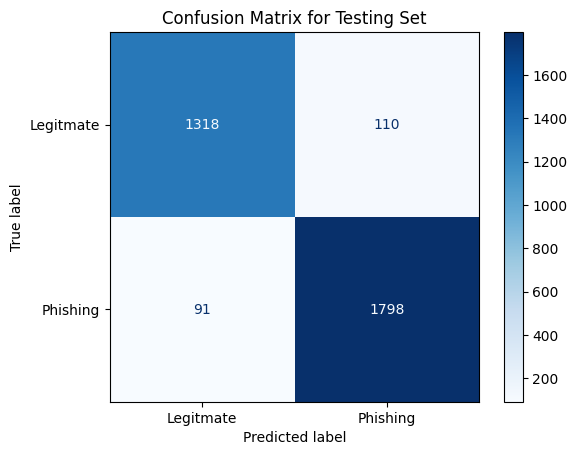

In [ ]:
test_predictions = (model.predict(test_x) > 0.5).astype("int32") # ? -> predict randon activities with the built linear regression model
cm = confusion_matrix(test_y, test_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Phishing', 'Legitimate'])
disp.plot(cmap="Blues")
plt.title('Confusion Matrix for Testing Set')
plt.savefig("mlp-class-confusionmatrix.png")
plt.show()


In [ ]:
print(confusion_matrix(test_y, test_predictions))
print(classification_report(test_y, test_predictions, target_names=['Phishing', 'Legitimate']))
print('The accuracy on the test set is equal to: %.4f ' % accuracy_score(test_y, test_predictions))

[[1318  110]
 [  91 1798]]
              precision    recall  f1-score   support

   Legitmate       0.94      0.92      0.93      1428
    Phishing       0.94      0.95      0.95      1889

    accuracy                           0.94      3317
   macro avg       0.94      0.94      0.94      3317
weighted avg       0.94      0.94      0.94      3317

The accuracy on the test set is equal to: 0.9394 


In [ ]:
train_predictions = (model.predict(train_x) > 0.5).astype("int32")
print(confusion_matrix(train_y, train_predictions))
print(classification_report(train_y, train_predictions, target_names=['Phishing', 'Legitimate']))
print('The accuracy on the training set is equal to: %.4f ' % accuracy_score(train_y, train_predictions))

242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
[[3254  216]
 [ 148 4120]]
              precision    recall  f1-score   support

   Legitmate       0.96      0.94      0.95      3470
    Phishing       0.95      0.97      0.96      4268

    accuracy                           0.95      7738
   macro avg       0.95      0.95      0.95      7738
weighted avg       0.95      0.95      0.95      7738

The accuracy on the training set is equal to: 0.9530 


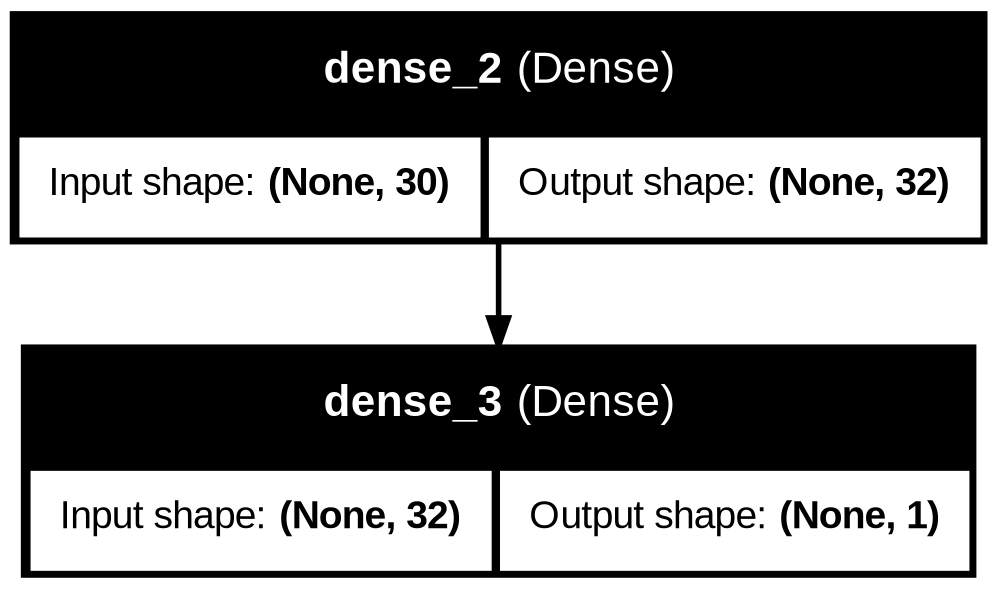

In [ ]:
# Save the model architecture as an image
plot_model(model, to_file='model_architecture.png', show_shapes=True, show_layer_names=True)